In [2]:
import numpy as np
import matplotlib.pyplot as plt
import datetime

In [3]:
from stonesoup.plotter import Plotter

import stonesoup.types.groundtruth as ssgt
import stonesoup.models.transition.linear as sstl

import stonesoup.types.detection as ssdet
import stonesoup.models.measurement.linear as ssmeas

# Non-SS Route

State 

\begin{align}
\mathbf{x}_k  = F_k \mathbf{x}_{k-1} + \mathbf{w}_k
\end{align}

Noise

\begin{align}
\mathbf{w}_k \sim \mathcal{N}(0,Q)
\end{align}

with

\begin{align}F_{k} &= \begin{bmatrix}
                    1 & \triangle t \\
                    0 & 1 \\
                    \end{bmatrix} \\
          Q_k &= \begin{bmatrix}
                  \frac{\triangle t^3}{3} & \frac{\triangle t^2}{2} \\
                  \frac{\triangle t^2}{2} & \triangle t \\
                 \end{bmatrix} q\end{align}

Text(0, 0.5, 'position')

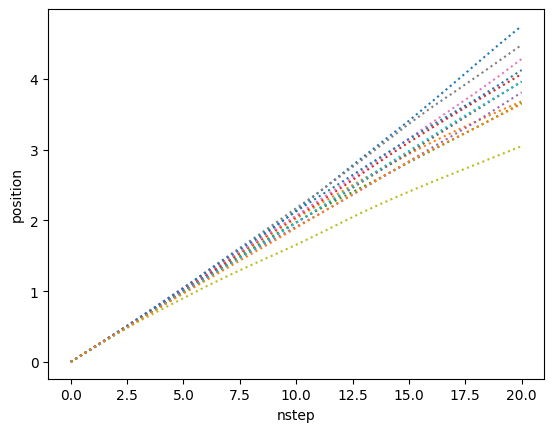

In [4]:
dt = 0.1
q = 0.05
v0 = 2
n_runs = 12

def update_state(x, q, dt):
    '''
    x is position, velocity state
    
    q scales noise
    dt scales time window / veloc
    '''
    
    # State transition model... position and veloc evolve via this matrix
    F = np.array([
        [1, dt],
        [0, 1],
    ])
    
    # Covariance matrix of position and veloc
    Q = q*np.array([
        [dt**3 / 3, dt**2 / 2],
        [dt**2 / 2, dt]
    ])
    
    # noise vector
    W = np.random.multivariate_normal(
        mean=np.zeros(2),
        cov=Q,
        size= 1 # n_samples
    )
    return F@x + W[0]

for _ in range(n_runs):
    x = np.array([0,v0])
    n_steperoonies = 20
    
    xs = [x]
    for i in range (n_steperoonies):
        x = update_state(x, q, dt)
        xs.append(x)
    
    xs = np.array(xs)
    
    plt.plot(xs[:,0],':')
plt.xlabel('nstep')
plt.ylabel('position')

# Stone Soup Equivalent

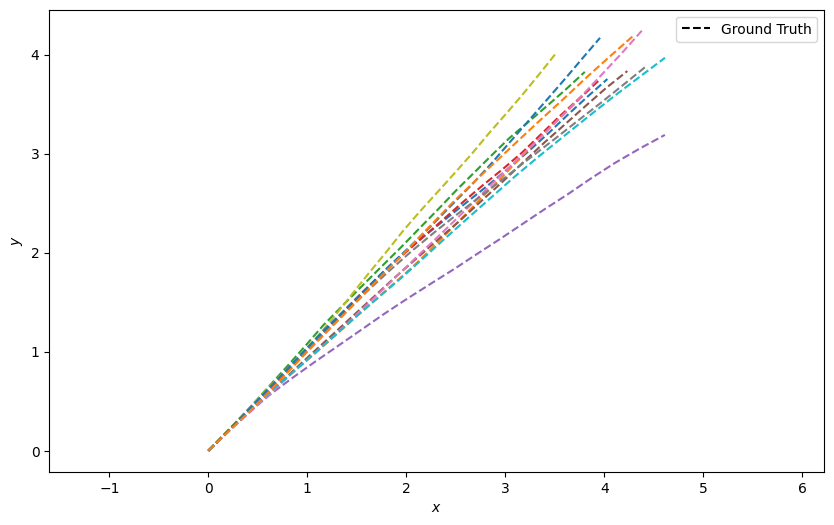

In [5]:
q_x = q
q_y = q

transition_model = sstl.CombinedLinearGaussianTransitionModel([
    sstl.ConstantVelocity(q_x),
    sstl.ConstantVelocity(q_y)
])

plotter = Plotter()
for _ in range(n_runs):
    start_time = datetime.datetime(1970,1,1,0)
    
    truth = ssgt.GroundTruthPath([ssgt.GroundTruthState([0, v0, 0, v0], timestamp=start_time)])
    
    num_steps = 20
    for k in range(1, num_steps + 1):
        truth.append(
            ssgt.GroundTruthState(
                transition_model.function(truth[k-1], noise=True, time_interval = datetime.timedelta(seconds=dt)),
                timestamp = start_time + datetime.timedelta(seconds=k)
            )
        )

    gobx = np.array([jib.state_vector[0] for jib in truth])
    goby = np.array([jib.state_vector[2] for jib in truth])
    plotter.plot_ground_truths(truth, [0, 2])

### Look at the matrices stone soup is using.

In [6]:
transition_model.matrix(time_interval=datetime.timedelta(seconds=dt))

array([[1. , 0.1, 0. , 0. ],
       [0. , 1. , 0. , 0. ],
       [0. , 0. , 1. , 0.1],
       [0. , 0. , 0. , 1. ]])

In [7]:
transition_model.covar(time_interval=datetime.timedelta(seconds=dt))

array([[1.66666667e-05, 2.50000000e-04, 0.00000000e+00, 0.00000000e+00],
       [2.50000000e-04, 5.00000000e-03, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 1.66666667e-05, 2.50000000e-04],
       [0.00000000e+00, 0.00000000e+00, 2.50000000e-04, 5.00000000e-03]])

# Simulating measurements
### We are only measuring x and y, not veloc

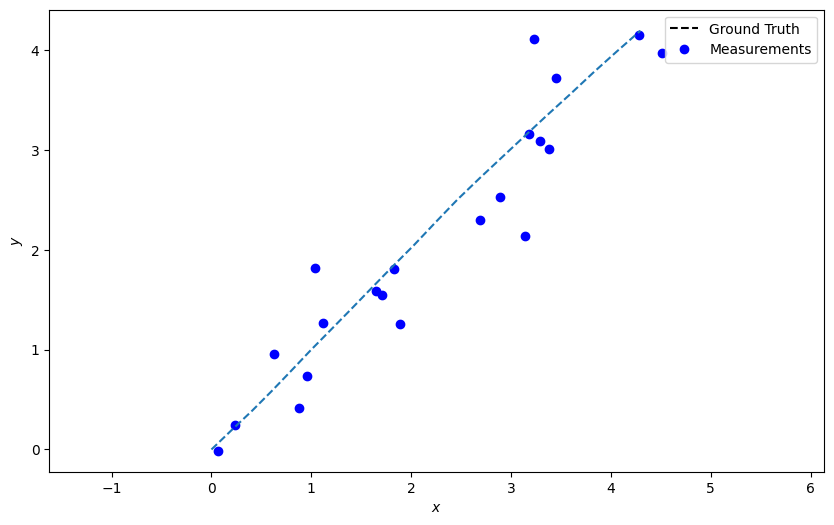

In [8]:
Q_synth = np.array([
    [0.1, 0],  # Covariance matrix for Gaussian PDF
    [0, 0.1]
])

measurement_model = ssmeas.LinearGaussian(
    ndim_state=4,  # Number of state dimensions (position and velocity in 2D)
    mapping=(0, 2),  # <--------------------------- we are only measuring x and y, not veloc
    noise_covar=Q_synth
    )

zs = []
for state in truth:
    z = measurement_model.function(state, noise = True)
    det = ssdet.Detection(
        z,
        timestamp = state.timestamp, 
        measurement_model = measurement_model
    )
    zs.append(det)

plotter = Plotter()
plotter.plot_ground_truths(truth, [0, 2])
plotter.plot_measurements(zs, [0, 2])

# Kalman Filter: Constant-Velocity Motion Model

## 1. Define the state vector

The state contains the 2D position and velocity:

$$
\mathbf{x}_k =
\begin{bmatrix}
p_x \\ v_x \\ p_y \\ v_y
\end{bmatrix}
$$

where $p_x, p_y$ are positions (m) and $v_x, v_y$ are velocities (m/s).

The Kalman filter maintains a state estimate $\hat{\mathbf{x}}_k$ and covariance matrix $P_k$, which describes uncertainty in that estimate.

## 2. Predict the state

Assuming constant velocity over timestep $\Delta t$:

$$
\hat{\mathbf{x}}_{k|k-1} = F\hat{\mathbf{x}}_{k-1|k-1}
$$

where

$$
F =
\begin{bmatrix}
1 & \Delta t & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & \Delta t \\
0 & 0 & 0 & 1
\end{bmatrix}
$$

## 3. Predict the uncertainty

$$
P_{k|k-1} = FP_{k-1|k-1}F^T + Q
$$

The previous covariance is propagated through the motion model, and $Q$ adds uncertainty from unpredictable motion.

For each axis, the process noise covariance is

$$
Q_{1D} = q
\begin{bmatrix}
\Delta t^3/3 & \Delta t^2/2 \\
\Delta t^2/2 & \Delta t
\end{bmatrix}
$$

The full $Q$ contains one such block for each axis, assuming independent process noise between X and Y.

## 4. Model the measurements

Only position is measured:

$$
\mathbf{z}_k = H\mathbf{x}_k + \mathbf{v}_k
$$

where

$$
H =
\begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 0 & 1 & 0
\end{bmatrix}
$$

The measurement noise covariance is

$$
R =
\begin{bmatrix}
\sigma^2 & 0 \\
0 & \sigma^2
\end{bmatrix}
$$

## 5. Calculate the innovation

The predicted measurement is

$$
\hat{\mathbf{z}}_{k|k-1} = H\hat{\mathbf{x}}_{k|k-1}
$$

The innovation is the difference between the actual and predicted measurements:

$$
\mathbf{y}_k = \mathbf{z}_k - H\hat{\mathbf{x}}_{k|k-1}
$$

## 6. Calculate the innovation covariance

$$
S_k = HP_{k|k-1}H^T + R
$$

This combines predicted measurement uncertainty with measurement noise.

## 7. Calculate the Kalman gain

$$
K_k = P_{k|k-1}H^T S_k^{-1}
$$

The Kalman gain determines how strongly the filter responds to the measurement. Greater predicted uncertainty generally increases the weight given to the measurement; greater measurement noise decreases it.

## 8. Correct the state estimate

$$
\hat{\mathbf{x}}_{k|k}
=
\hat{\mathbf{x}}_{k|k-1} + K_k\mathbf{y}_k
$$

The filter corrects its prediction using the innovation weighted by the Kalman gain. Velocity estimates can also improve, even though velocity is not measured directly.

## 9. Update the uncertainty

$$
P_{k|k} = P_{k|k-1} - K_kHP_{k|k-1}
$$

A numerically more robust alternative is the Joseph form:

$$
\begin{aligned}
P_{k|k} ={}&
(I-K_kH)P_{k|k-1}(I-K_kH)^T \\
&+ K_kRK_k^T
\end{aligned}
$$

This form helps preserve covariance symmetry and positive semidefiniteness in finite-precision arithmetic.

## 10. Repeat for the next timestep

The updated estimate and covariance become the starting point for the next iteration:

$$
\hat{\mathbf{x}}_{k-1|k-1} \leftarrow \hat{\mathbf{x}}_{k|k}
$$

$$
P_{k-1|k-1} \leftarrow P_{k|k}
$$

## 11. Interpret the covariance and uncertainty ellipse

The diagonal entries of $P_k$ give the marginal variances of the state components. Taking their square roots gives the corresponding standard deviations.

The position covariance submatrix is

$$
P_{\mathrm{pos}} =
\begin{bmatrix}
P_{00} & P_{02} \\
P_{20} & P_{22}
\end{bmatrix}
$$

The diagonal entries describe X and Y variances; the off-diagonal entries describe covariance between X and Y.

Diagonalising the position covariance gives

$$
P_{\mathrm{pos}} = V\Lambda V^T
$$

The columns of $V$ are the eigenvectors, which give the ellipse's principal directions. The eigenvalues in $\Lambda$ give the variances along those directions.

For a 2D Gaussian, the 95% confidence ellipse has semi-axis lengths

$$
a_i = \sqrt{5.991\,\lambda_i}
$$

Here, $\lambda_i$ is an eigenvalue of $P_{\mathrm{pos}}$, and 5.991 is the 95th percentile of the chi-squared distribution with two degrees of freedom.

## Summary

The Kalman filter alternates between predicting motion and uncertainty, then using each new position measurement to correct both the state estimate and its uncertainty.

# Non-SS Kalman

In [9]:
zs_list = [np.array(_.state_vector) for _ in zs]

In [10]:
dt = 0.1 # timestep
q = 0.05 # process noise
sig = 0.1 # measurement standard deviation
v0 = 1 # velocity initial guess

# Motion transition model
F = np.array([
    [1, dt, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, dt],
    [0, 0, 0, 1]
]) 

# Measurement mapping (measurements only measure positions )
# Measurement model will be z = H@x + v, where v has covariance matrix R
H = np.array([
    [1, 0, 0, 0],
    [0, 0, 1, 0]
])

# Process noise covariance (accounting for random accelerations)
Q_1d = q*np.array([
    [dt**3 / 3, dt**2 / 2],
    [dt**2 / 2, dt]
])
Q = np.zeros((4, 4))
Q[np.ix_([0, 1], [0, 1])] = Q_1d
Q[np.ix_([2, 3], [2, 3])] = Q_1d

# Measurement noise covariance
R = np.array([
    [sig**2, 0],
    [0, sig**2]
])

# Initial state guess
x_prev = np.array([
    [zs_list[0][0][0]],
    [v0],
    [zs_list[0][1][0]],
    [v0]
])

# Initial uncertainty
P_prev = np.diag([
    5**2,  # Variance of px: 25 m²
    2**2,  # Variance of vx: 4 (m/s)²
    5**2,  # Variance of py: 25 m²
    2**2   # Variance of vy: 4 (m/s)²
])

xs_list = [x_prev]
Ps_list = [P_prev]

# discard initial measurement, because we've directly used this z in prediction
for z in zs_list[1:]:
    ## 1. PREDICT STATE
    # x is state for step k, given state for k-1
    # F is transition model
    # x_prev is previous state
    x = F@x_prev
    
    # uncertainty
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    # P_prev is uncertainty (not probability) in previous state
    # Q is the uncertainty due to unpredictable motion (random acceleration, for example)
    P = F@P_prev@F.T + Q
    
    ## 2. COMPARE WITH MEASUREMENT
    
    # y is "innovation" for step k
    # z is measurement for step k
    # x is state for step k, given state for k-1
    # H@x is predicted measurement
    y = z - H@x
    
    # Kalman gain
    # S is innovation covartiance for step k
    # P here is uncertainty (not probability) of state k given state k-1 happened
    # R is measurement noise covariance
    # K is Kalman gain
    S = H@P@H.T + R
    K = P@H.T@np.linalg.inv(S)
    
    
    ## 3. CORRECT THE STATE ESTIMATE
    # Updated estimate (x_new) equals predicted state (x) plus kalman gain (K) times innovation (y)
    x_new = x + K@y
    
    ## 4. UPDATE THE UNCERTAINTY
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    
    P_new = P - K@H@P
    #    # "Joseph form", apparently has better floating point arithmetic
    #    I = np.eye(P.shape[0])
    #
    #    P_new = (
    #        (I - K @ H) @ P @ (I - K @ H).T
    #        + K @ R @ K.T
    #    )

    ## 5. PREP FOR NEXT ITERATION
    x_prev = x_new
    P_prev = P_new

    xs_list.append(x_new)
    Ps_list.append(P_new)

In [12]:
xs_list

[array([[0.23817096],
        [1.        ],
        [0.2471396 ],
        [1.        ]]),
 array([[ 0.06593794],
        [ 0.99564851],
        [-0.01224564],
        [ 0.99425544]]),
 array([[0.7601399 ],
        [5.75304051],
        [0.35786385],
        [3.15986136]]),
 array([[1.0389602 ],
        [4.05709732],
        [0.7193271 ],
        [3.41999908]]),
 array([[0.88605783],
        [1.69492535],
        [0.99201917],
        [3.12692087]]),
 array([[1.09159934],
        [1.8155285 ],
        [1.28468179],
        [3.05991154]]),
 array([[1.14844019],
        [1.46779195],
        [1.71092222],
        [3.39520461]]),
 array([[1.57074666],
        [2.13517197],
        [1.68073052],
        [2.4996907 ]]),
 array([[1.80145393],
        [2.17263305],
        [1.87980979],
        [2.38879023]]),
 array([[1.89428496],
        [1.9211365 ],
        [1.89316093],
        [1.9329641 ]]),
 array([[1.92258113],
        [1.60602641],
        [1.90064724],
        [1.57555023]]),
 array

In [20]:
z

array([[4.50974411],
       [3.97364518]])

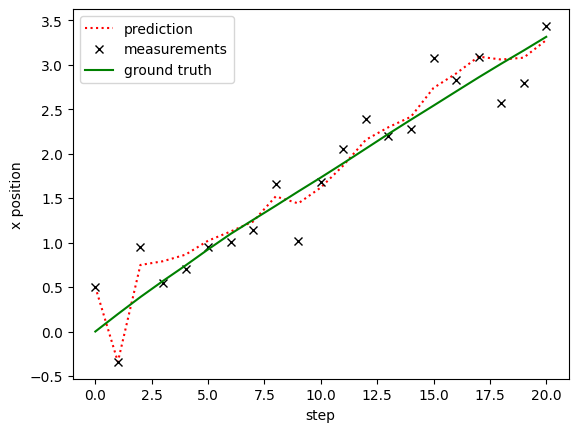

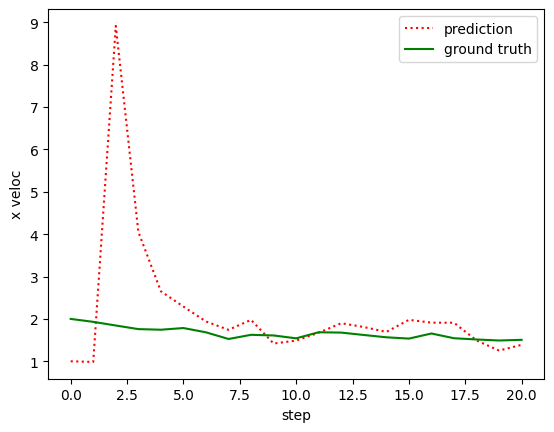

In [31]:
X0_vals = [np.array(_.state_vector)[0] for _ in truth]
x0_vals = [_[0] for _ in xs_list]
z0_vals = [_[0] for _ in zs_list]

X1_vals = [np.array(_.state_vector)[1] for _ in truth]
x1_vals = [_[1] for _ in xs_list]
#z1_vals not applicable.... we don't measure velocity

plt.figure()
plt.plot(x0_vals, 'r:')
plt.plot(z0_vals, 'kx')
plt.plot(X0_vals, 'g-')
plt.xlabel("step")
plt.ylabel("x position")
plt.legend(["prediction", "measurements", "ground truth"])

plt.figure()
plt.plot(x1_vals, 'r:')
# Z1 vals not applicable
plt.plot(X1_vals, 'g-')
plt.xlabel("step")
plt.ylabel("x veloc")
plt.legend(["prediction", "ground truth"])

# Uncertainty evolution

- The uncertainty along a specific axis is given by the diagonals of P (the variances)
- The uncertainty along the ellipse's axes is given by the eigen values


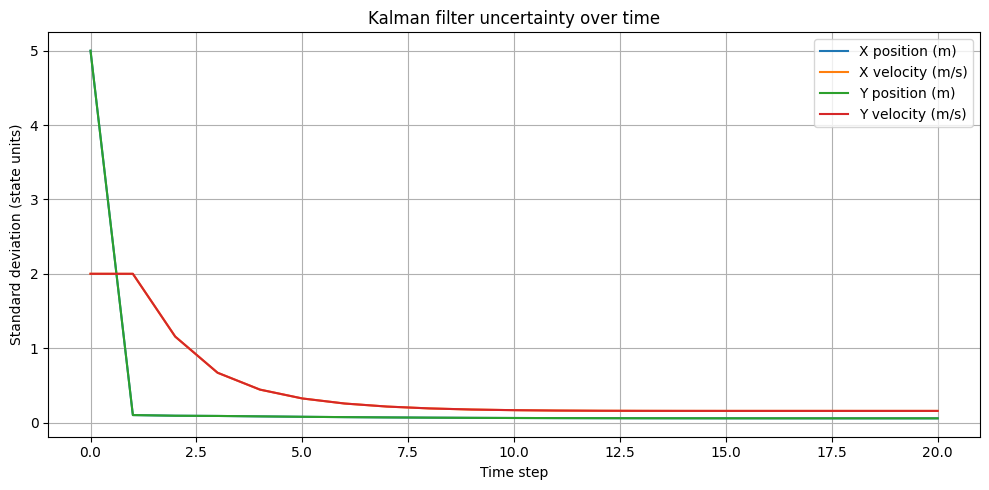

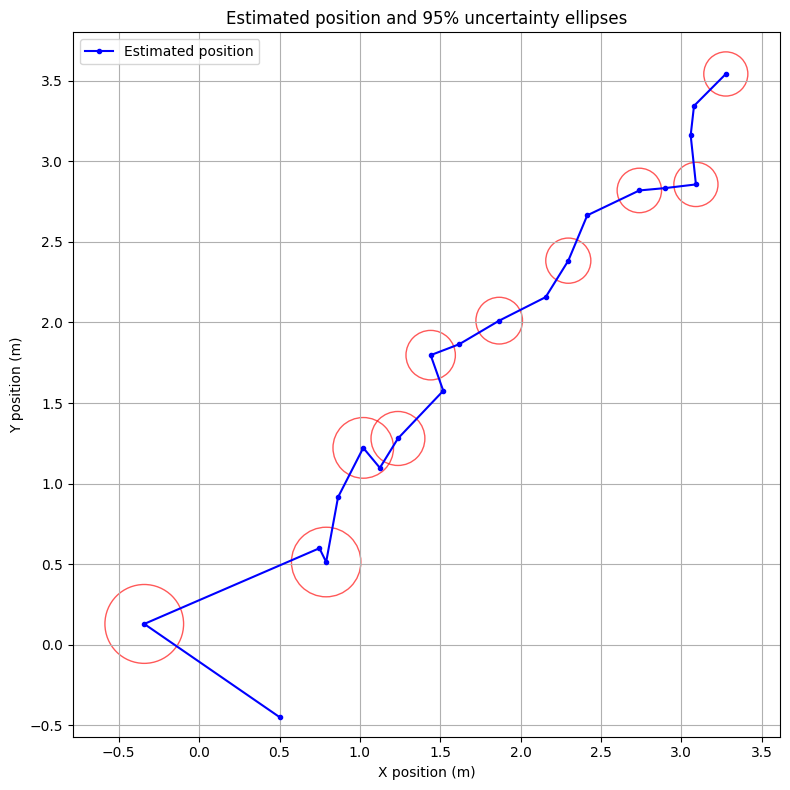

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Convert state estimates and covariance matrices to arrays
X = np.array([np.asarray(x).ravel() for x in xs_list])
Ps = np.array(Ps_list)

steps = np.arange(len(Ps))

# --------------------------------------------------
# Plot 1: How uncertainty changes over time
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

state_labels = [
    "X position (m)",
    "X velocity (m/s)",
    "Y position (m)",
    "Y velocity (m/s)"
]

for i, label in enumerate(state_labels):
    # Diagonal entries of P are variances.
    # Take the square root to get standard deviation.
    std = np.sqrt(np.maximum(Ps[:, i, i], 0))
    ax.plot(steps, std, label=label)

ax.set_title("Kalman filter uncertainty over time")
ax.set_xlabel("Time step")
ax.set_ylabel("Standard deviation (state units)")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Plot 2: Position uncertainty ellipses
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(X[:, 0], X[:, 2], "b.-", label="Estimated position")

# 95% confidence ellipse for a 2D Gaussian:
# sqrt(chi-square quantile with 2 degrees of freedom)
scale = np.sqrt(5.991)

# Draw a manageable number of ellipses
indices = np.unique(
    np.linspace(1, len(X) - 1, min(10, len(X)), dtype=int)
)

for i in indices:
    # Position covariance for [px, py].
    # State order is [px, vx, py, vy].
    P_pos = Ps[i][np.ix_([0, 2], [0, 2])]

    # Eigenvectors give ellipse directions;
    # eigenvalues give squared axis lengths.
    eigenvalues, eigenvectors = np.linalg.eigh(P_pos)
    eigenvalues = np.maximum(eigenvalues, 0)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    # Ellipse width and height are full axis lengths
    width, height = 2 * scale * np.sqrt(eigenvalues)

    ellipse = Ellipse(
        xy=(X[i, 0], X[i, 2]),
        width=width,
        height=height,
        angle=angle,
        fill=False,
        edgecolor="red",
        alpha=0.65
    )
    ax.add_patch(ellipse)

ax.set_title("Estimated position and 95% uncertainty ellipses")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()


# Stonesoup Kalman

### A "track" is just a history of estimates...

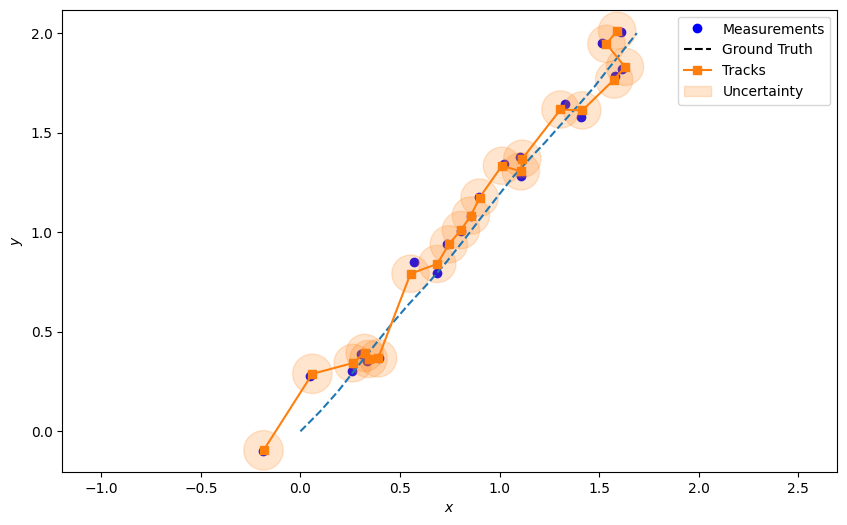

In [55]:
from stonesoup.predictor.kalman import KalmanPredictor
from stonesoup.updater.kalman import KalmanUpdater
from stonesoup.types.state import GaussianState
from stonesoup.types.hypothesis import SingleHypothesis
from stonesoup.types.track import Track

q =  0.05
Q_synth = np.array([
    [0.01, 0],  # Covariance matrix for Gaussian PDF
    [0, 0.01]
])

transition_model = sstl.CombinedLinearGaussianTransitionModel([
    sstl.ConstantVelocity(q),
    sstl.ConstantVelocity(q)
])

measurement_model = ssmeas.LinearGaussian(
    ndim_state=4,  # Number of state dimensions (position and velocity in 2D)
    mapping=(0, 2),  # <--------------------------- we are only measuring x and y, not veloc
    noise_covar=Q_synth
)

truth = ssgt.GroundTruthPath([ssgt.GroundTruthState([0, v0, 0, v0], timestamp=start_time)])

num_steps = 20
for k in range(1, num_steps + 1):
    truth.append(
        ssgt.GroundTruthState(
            transition_model.function(truth[k-1], noise=True, time_interval = datetime.timedelta(seconds=dt)),
            timestamp = start_time + datetime.timedelta(seconds=k)
        )
    )

predictor = KalmanPredictor(transition_model)
updater = KalmanUpdater(measurement_model)
prior = GaussianState([[0], [v0], [0], [v0]], np.diag([0.5, 0.5, 0.5, 0.5]), timestamp=start_time)

measurements = []
for state in truth:
    measurement = measurement_model.function(state, noise=True)
    measurements.append(ssdet.Detection(measurement,
                                  timestamp=state.timestamp,
                                  measurement_model=measurement_model))
    
track = Track()
for measurement in measurements:
    prediction = predictor.predict(prior, timestamp=measurement.timestamp)
    hypothesis = SingleHypothesis(prediction, measurement)  # Group a prediction and measurement
    post = updater.update(hypothesis)
    track.append(post)
    prior = track[-1]
    
plotter = Plotter()
plotter.plot_measurements(measurements, [0, 2])
plotter.plot_ground_truths(truth, [0, 2])
_=plotter.plot_tracks(track, [0, 2], uncertainty=True)